# EDA tập train NASA C-MAPSS FD001

Học viên: Phan Nguyễn Mai Phương — MSHV 25002711

Notebook này xem nhanh dữ liệu train FD001: mỗi động cơ sống được bao lâu, 3 thiết lập vận hành
(operational setting) và 21 sensor thay đổi thế nào theo thời gian, và sensor nào có liên hệ rõ với RUL.
Ở bước này chỉ dùng file `train_FD001.txt`; tập test để dành cho lúc đánh giá mô hình.
Các bảng và hình được lưu vào `outputs/eda/` để báo cáo và dashboard dùng lại.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from cmapss.data.contracts import KEY, MEASUREMENTS, SENSORS, SETTINGS
from cmapss.data.readers import read_observations
from cmapss.data.targets import make_train_targets
from cmapss.eda import describe_measurements, select_example_engines, sensor_rul_correlations

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
RAW_PATH = ROOT / "data/raw/train_FD001.txt"
OUTPUT = ROOT / "outputs/eda"
TABLES = OUTPUT / "tables"
FIGURES = OUTPUT / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 100})

In [2]:
def save_table(table, filename):
    table.to_csv(TABLES / filename, index=False, float_format="%.12g", na_rep="NaN")


def show_figure(fig, filename, show=True):
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight", facecolor="white")
    if show:
        display(fig)
    plt.close(fig)

## 1. Đọc dữ liệu

Mỗi dòng của file train là một động cơ tại một cycle. Vì mỗi động cơ được chạy đến khi hỏng,
RUL (Remaining Useful Life, số cycle còn lại trước khi hỏng) tính được trực tiếp:
RUL = cycle cuối của động cơ − cycle hiện tại. Ví dụ động cơ hỏng ở cycle 200 thì tại cycle 170 còn RUL = 30.

In [3]:
observations = read_observations(RAW_PATH, split="train")
targets = make_train_targets(observations)
train = observations.merge(targets, on=list(KEY), how="left")
assert train["engine_id"].nunique() == 100

input_summary = pd.DataFrame([{
    "split": "train", "observations": len(train), "engines": train.engine_id.nunique(),
    "raw_columns": len(observations.columns) - 1,
    "missing_values": int(train.isna().sum().sum()),
    "duplicate_keys": int(train.duplicated(list(KEY)).sum()),
}])
schema = pd.DataFrame({"column": train.columns, "dtype": train.dtypes.astype(str).values})
save_table(input_summary, "input_summary.csv")
save_table(schema, "schema.csv")
input_summary

,split,observations,engines,raw_columns,missing_values,duplicate_keys
0,train,20631,100,26,0,0


**Nhận xét.** File train có 20.631 dòng của 100 động cơ, 26 cột gốc (id, cycle, 3 setting, 21 sensor).
Không có giá trị thiếu và không có khóa `(split, engine_id, cycle)` nào bị trùng, nên có thể đi thẳng vào phân tích.

## 2. Tuổi thọ của động cơ

Tuổi thọ của một động cơ là cycle cuối cùng trong file train. Mỗi động cơ cho một giá trị.

In [4]:
lifetimes = train.groupby("engine_id", as_index=False).agg(
    first_cycle=("cycle", "min"), last_cycle=("cycle", "max"), n_observations=("cycle", "size")
)
lifetime_summary = lifetimes.last_cycle.describe().rename_axis("statistic").reset_index(name="cycles")
rul_summary = train.rul.describe().rename_axis("statistic").reset_index(name="cycles")
save_table(lifetimes, "engine_lifetimes.csv")
save_table(lifetime_summary, "lifetime_summary.csv")
save_table(rul_summary, "rul_summary.csv")

pd.DataFrame({"tuổi thọ (mỗi động cơ)": lifetime_summary.set_index("statistic").cycles,
              "RUL (mỗi dòng)": rul_summary.set_index("statistic").cycles}).round(2)

,tuổi thọ (mỗi động cơ),RUL (mỗi dòng)
statistic,,
count,100.00,20631.00
mean,206.31,107.81
std,46.34,68.88
min,128.00,0.00
25%,177.00,51.00
50%,199.00,103.00
75%,229.25,155.00
max,362.00,361.00


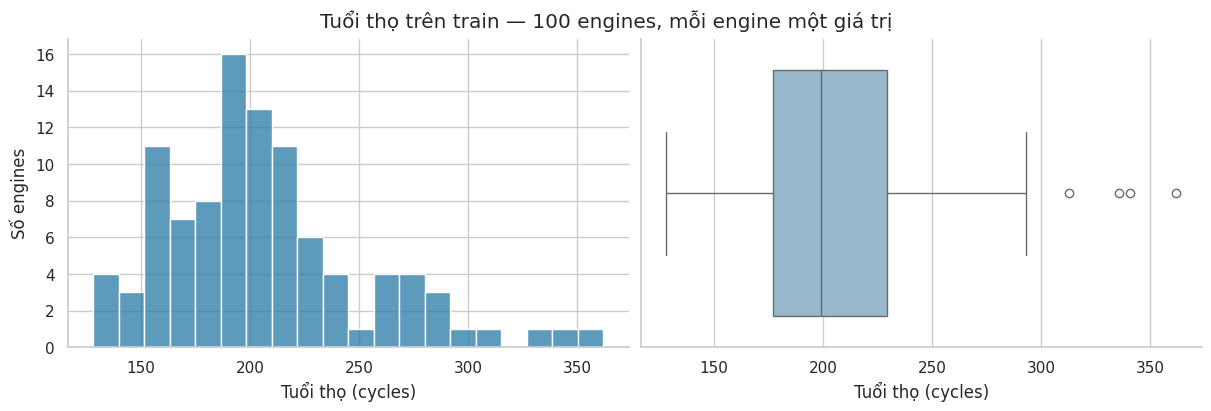

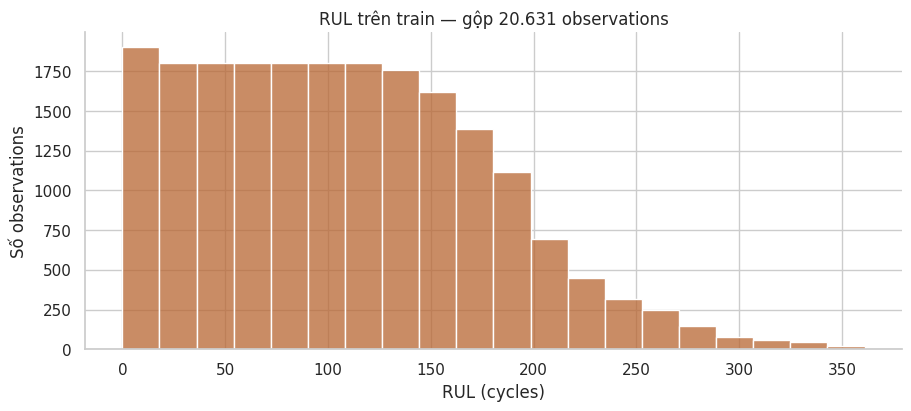

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
sns.histplot(lifetimes, x="last_cycle", bins=20, ax=axes[0], color="#2878a5")
sns.boxplot(lifetimes, x="last_cycle", ax=axes[1], color="#8dbbd3")
axes[0].set(xlabel="Tuổi thọ (cycles)", ylabel="Số engines")
axes[1].set(xlabel="Tuổi thọ (cycles)", yticks=[])
fig.suptitle("Tuổi thọ trên train — 100 engines, mỗi engine một giá trị")
show_figure(fig, "engine_lifetimes.png")

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
sns.histplot(train, x="rul", bins=20, ax=ax, color="#b86632")
ax.set(title="RUL trên train — gộp 20.631 observations",
       xlabel="RUL (cycles)", ylabel="Số observations")
show_figure(fig, "rul_distribution.png")

**Nhận xét.** Tuổi thọ dao động từ 128 đến 362 cycle, median 199, trung bình 206,3. Phân phối lệch phải:
Q75 chỉ là 229, nhưng có 4 động cơ sống trên 300 cycle (313, 336, 341, 362) và nằm ngoài whisker của boxplot.
Tôi giữ nguyên các động cơ này vì đó là chuỗi chạy đến hỏng hợp lệ, không phải lỗi đo.

Hình RUL thì khác: nó đếm theo dòng chứ không theo động cơ, nên động cơ sống lâu đóng góp nhiều dòng hơn.
Median RUL trên các dòng là 103 cycle. Cột histogram thấp dần về bên phải vì chỉ những động cơ sống lâu
mới có dòng với RUL lớn.

## 3. Thống kê mô tả 3 setting và 21 sensor

Ngoài thống kê trên toàn tập train, tôi tính thêm số giá trị khác nhau trong từng động cơ.
Lý do là một sensor có thể thay đổi trên toàn tập nhưng lại đứng yên trong nhiều động cơ.

In [6]:
measurement_summary = describe_measurements(train, MEASUREMENTS)
save_table(measurement_summary, "measurement_summary.csv")
constant_measurements = measurement_summary.loc[measurement_summary.is_constant, "measurement"].tolist()

measurement_summary[["measurement", "mean", "std", "min", "max", "n_unique", "is_constant"]].round(4)

,measurement,mean,std,min,max,n_unique,is_constant
0,setting_1,-0.0000,0.0022,-0.0087,0.0087,158,False
1,setting_2,0.0000,0.0003,-0.0006,0.0006,13,False
2,setting_3,100.0000,0.0000,100.0000,100.0000,1,True
3,sensor_1,518.6700,0.0000,518.6700,518.6700,1,True
4,sensor_2,642.6809,0.5001,641.2100,644.5300,310,False
5,sensor_3,1590.5231,6.1311,1571.0400,1616.9100,3012,False
6,sensor_4,1408.9338,9.0006,1382.2500,1441.4900,4051,False
7,sensor_5,14.6200,0.0000,14.6200,14.6200,1,True
8,sensor_6,21.6098,0.0014,21.6000,21.6100,2,False
9,sensor_7,553.3677,0.8851,549.8500,556.0600,513,False


In [7]:
long_measurements = train.melt(id_vars="engine_id", value_vars=list(MEASUREMENTS),
                               var_name="measurement", value_name="value")
within_engine = long_measurements.groupby(["engine_id", "measurement"], as_index=False).agg(
    n_observations=("value", "size"), n_unique=("value", "nunique"),
    min=("value", "min"), max=("value", "max"), mean=("value", "mean"), std=("value", "std")
)
within_engine["range"] = within_engine["max"] - within_engine["min"]
within_engine["is_constant"] = within_engine.n_unique.eq(1)
constant_counts = within_engine.groupby("measurement", as_index=False).agg(
    constant_engines=("is_constant", "sum"), total_engines=("engine_id", "size")
)
save_table(within_engine, "within_engine_variability.csv")
save_table(constant_counts, "constant_engine_counts.csv")

# chỉ hiện các cột đứng yên trong ít nhất một động cơ
constant_counts[constant_counts.constant_engines > 0]

,measurement,constant_engines,total_engines
0,sensor_1,100,100
1,sensor_10,100,100
7,sensor_16,100,100
9,sensor_18,100,100
10,sensor_19,100,100
16,sensor_5,100,100
17,sensor_6,38,100
23,setting_3,100,100


**Nhận xét.** Có 7 cột không đổi trên toàn tập train: `setting_3` và các sensor 1, 5, 10, 16, 18, 19.
Các cột này không mang thông tin gì cho bài toán RUL trên FD001.
`sensor_6` là trường hợp lưng chừng: nó chỉ có hai giá trị 21,60 và 21,61, và đứng yên hoàn toàn
trong 38/100 động cơ. Nếu chỉ nhìn bảng toàn cục thì sẽ không thấy điều này.
`setting_1` và `setting_2` chỉ dao động rất nhỏ quanh 0 (trong khoảng ±0,0087 và ±0,0006),
phù hợp với việc FD001 chỉ có một điều kiện vận hành.

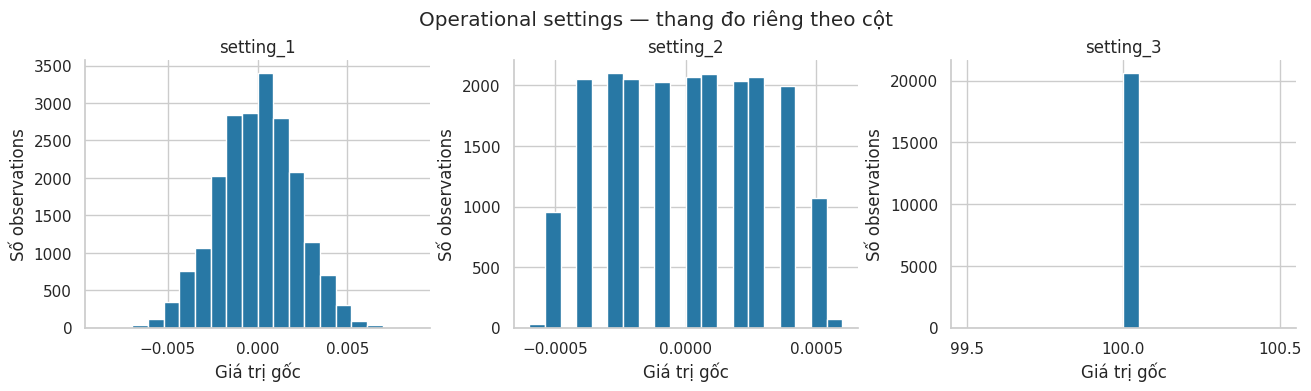

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, setting in zip(axes, SETTINGS):
    ax.hist(train[setting], bins=20, color="#2878a5", edgecolor="white")
    ax.set(title=setting, xlabel="Giá trị gốc", ylabel="Số observations")
    ax.ticklabel_format(style="plain", useOffset=False, axis="x")
    ax.locator_params(axis="x", nbins=3)
fig.suptitle("Operational settings — thang đo riêng theo cột")
show_figure(fig, "settings_distributions.png")

Histogram của 21 sensor dài ba trang nên tôi chỉ lưu vào `outputs/eda/figures/sensor_distributions_*.png`
và hiện trang 2 (sensor 8 đến 14), là trang có nhiều điều đáng nói nhất.

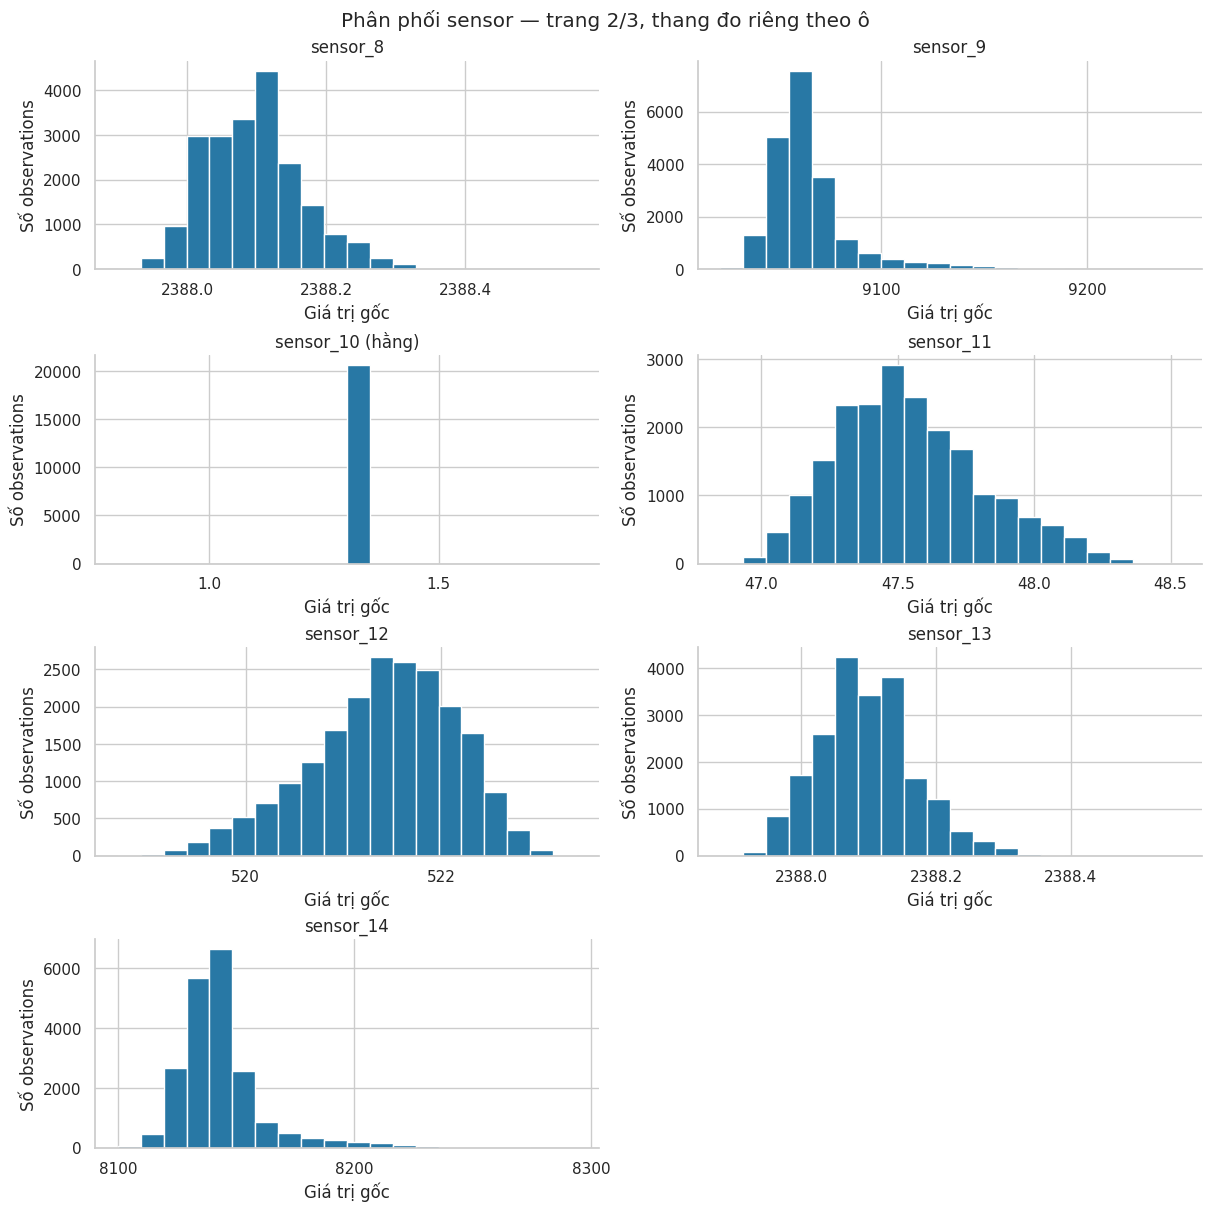

In [9]:
for page in range(3):
    sensors = SENSORS[page * 7:(page + 1) * 7]
    fig, axes = plt.subplots(4, 2, figsize=(12, 12), layout="constrained")
    for ax, sensor in zip(axes.flat, sensors):
        ax.hist(train[sensor], bins=20, color="#2878a5", edgecolor="white")
        suffix = " (hằng)" if sensor in constant_measurements else ""
        ax.set(title=sensor + suffix, xlabel="Giá trị gốc", ylabel="Số observations")
        ax.ticklabel_format(style="plain", useOffset=False, axis="x")
        ax.locator_params(axis="x", nbins=4)
    axes.flat[-1].set_visible(False)
    fig.suptitle(f"Phân phối sensor — trang {page + 1}/3, thang đo riêng theo ô")
    show_figure(fig, f"sensor_distributions_{page + 1}.png", show=(page == 1))

**Nhận xét.** `sensor_11` và `sensor_12` có dạng gần chuông, hơi lệch về một phía.
`sensor_9` và `sensor_14` thì khác hẳn: phần lớn giá trị dồn ở bên trái và có đuôi dài bên phải
(`sensor_9` lên tới 9.245 trong khi median chỉ 9.061). Đuôi này đến từ một số động cơ có giá trị
tăng mạnh ở cuối đời, sẽ thấy rõ hơn ở mục 4.

## 4. Quỹ đạo sensor trên ba động cơ

Để xem sensor thay đổi theo thời gian, tôi chọn ba động cơ có tuổi thọ gần Q25, median và Q75 nhất.
Chọn theo tuổi thọ để không bị thiên về những đường đẹp.

In [10]:
examples = select_example_engines(lifetimes)
save_table(examples, "example_engines.csv")
example_ids = examples.engine_id.drop_duplicates().tolist()
colors = sns.color_palette("colorblind", n_colors=len(example_ids))
examples

,quantile,target_lifetime,engine_id,last_cycle
0,0.25,177.00,87,178
1,0.50,199.00,26,199
2,0.75,229.25,75,229


In [11]:
# ba trang quỹ đạo của đủ 21 sensor, chỉ lưu file
for page in range(3):
    sensors = SENSORS[page * 7:(page + 1) * 7]
    fig, axes = plt.subplots(4, 2, figsize=(12, 12), layout="constrained")
    for ax, sensor in zip(axes.flat, sensors):
        for engine_id, color in zip(example_ids, colors):
            engine = train[train.engine_id.eq(engine_id)].sort_values("cycle")
            ax.plot(engine.cycle, engine[sensor], color=color, linewidth=1, alpha=0.8,
                    label=f"Engine {engine_id}: {engine.cycle.max()} cycles")
        ax.set(title=sensor, xlabel="Cycle", ylabel="Giá trị gốc")
        ax.ticklabel_format(style="plain", useOffset=False, axis="y")
    legend_ax = axes.flat[-1]
    legend_ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", frameon=False)
    fig.suptitle(f"Quỹ đạo sensor — trang {page + 1}/3; engines chọn theo tuổi thọ")
    show_figure(fig, f"sensor_trajectories_{page + 1}.png", show=False)

Ba trang trên nằm trong `outputs/eda/figures/sensor_trajectories_*.png`. Ở đây chỉ vẽ lại bốn sensor
đáng chú ý nhất.

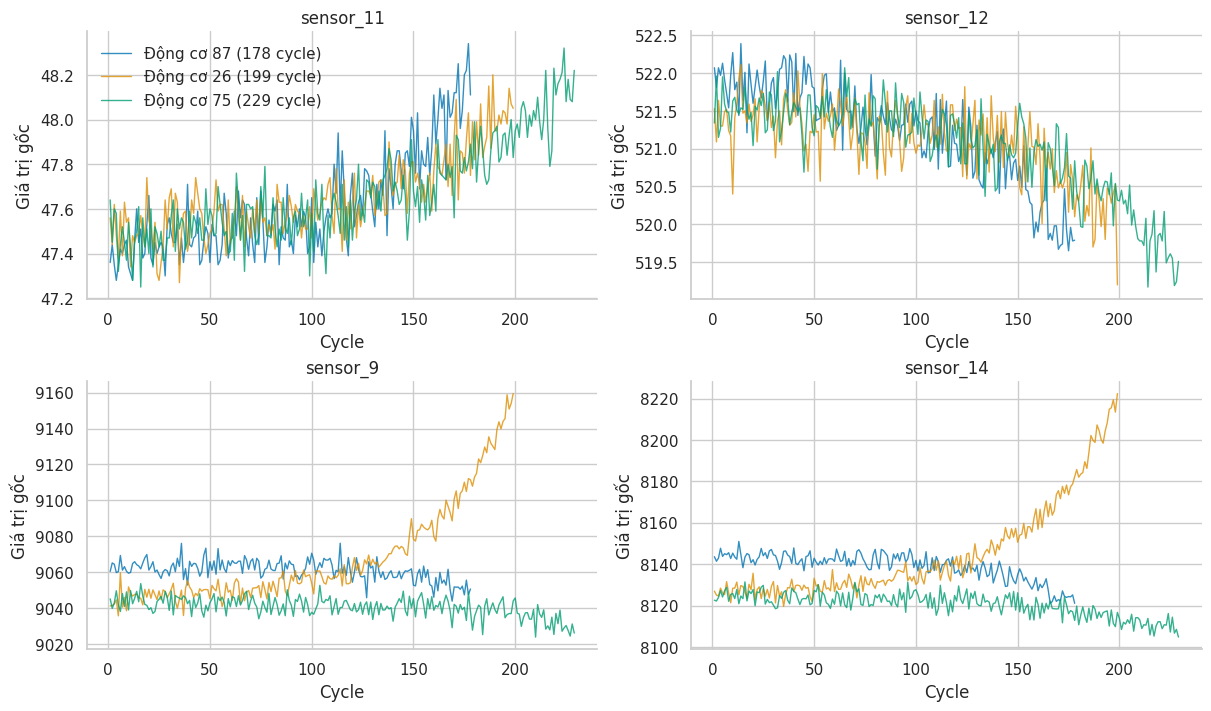

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, sensor in zip(axes.flat, ["sensor_11", "sensor_12", "sensor_9", "sensor_14"]):
    for engine_id, color in zip(example_ids, colors):
        engine = train[train.engine_id.eq(engine_id)]
        ax.plot(engine.cycle, engine[sensor], color=color, linewidth=1, alpha=0.8,
                label=f"Động cơ {engine_id} ({engine.cycle.max()} cycle)")
    ax.set(title=sensor, xlabel="Cycle", ylabel="Giá trị gốc")
axes[0, 0].legend(frameon=False)
plt.show()

**Nhận xét.** Trên cả ba động cơ 87, 26 và 75, `sensor_11` gần như phẳng trong khoảng 100 cycle đầu rồi tăng dần
về cuối đời, còn `sensor_12` thì giảm dần;
đây là kiểu suy giảm rõ và nhất quán. `sensor_9` và `sensor_14` thì không như vậy: động cơ 26 tăng vọt ở cuối,
còn hai động cơ kia gần như đi ngang hoặc giảm nhẹ. Vậy không thể nói mọi sensor cùng đi theo một hướng
khi động cơ xuống cấp. Ba động cơ là quá ít để kết luận, nên mục 5 kiểm tra lại trên cả 100 động cơ.

## 5. Tương quan Spearman

Spearman rho đo mức liên hệ đơn điệu dựa trên thứ hạng: rho gần −1 nghĩa là khi một biến tăng thì biến kia
gần như luôn giảm, kể cả khi quan hệ không tuyến tính. Đầu tiên là tương quan giữa các sensor, gộp mọi dòng.

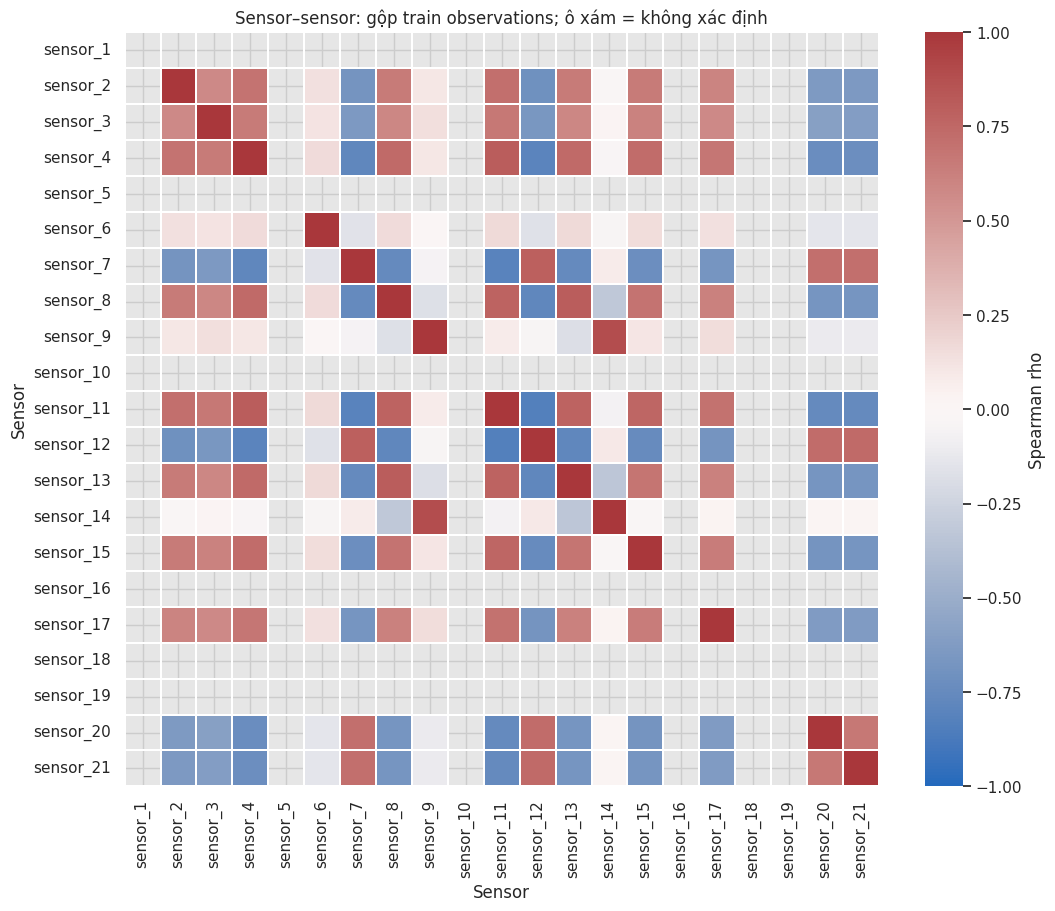

In [13]:
sensor_correlation = train[list(SENSORS)].corr(method="spearman")
sensor_correlation.index.name = "sensor"
save_table(sensor_correlation.reset_index(), "sensor_spearman_pooled.csv")

fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
ax.set_facecolor("#e6e6e6")
sns.heatmap(sensor_correlation, vmin=-1, vmax=1, center=0, cmap="vlag", square=True,
            ax=ax, cbar_kws={"label": "Spearman rho"}, linewidths=0.15)
ax.set(title="Sensor–sensor: gộp train observations; ô xám = không xác định",
       xlabel="Sensor", ylabel="Sensor")
show_figure(fig, "sensor_spearman_pooled.png")

**Nhận xét.** Các ô xám là 6 sensor hằng, không tính được tương quan. Phần còn lại chia thành hai khối rõ:
nhóm sensor 2, 3, 4, 8, 11, 13, 15, 17 cùng tăng với nhau, và nhóm 7, 12, 20, 21 đi ngược lại
(ví dụ `sensor_11` với `sensor_12` có rho = −0,83). `sensor_9` và `sensor_14` tương quan mạnh với nhau
(rho = 0,89) nhưng gần như không liên quan tới các sensor khác. Nhiều sensor mang thông tin trùng nhau,
điều này cần nhớ khi chọn đặc trưng cho mô hình.

Với quan hệ sensor–RUL, tôi không gộp mọi dòng mà tính riêng cho từng động cơ, được 100 hệ số cho mỗi sensor,
rồi xem median và độ phân tán của chúng. Cách này tránh việc động cơ sống lâu chiếm trọng số lớn hơn.
Sensor hằng trong một động cơ cho hệ số không xác định (NaN).

In [14]:
correlations = sensor_rul_correlations(train, SENSORS)
save_table(correlations, "sensor_rul_by_engine.csv")
correlation_summary = correlations.groupby("sensor")["rho"].describe().rename(
    columns={"count": "defined_engines", "25%": "q25", "50%": "median", "75%": "q75"}
).reindex(SENSORS)
correlation_summary["undefined_engines"] = 100 - correlation_summary.defined_engines
save_table(correlation_summary.reset_index(), "sensor_rul_summary.csv")

correlation_summary[["defined_engines", "q25", "median", "q75"]].dropna().round(3)

,defined_engines,q25,median,q75
sensor,,,,
sensor_2,100.0,-0.707,-0.671,-0.625
sensor_3,100.0,-0.678,-0.637,-0.585
sensor_4,100.0,-0.804,-0.784,-0.759
sensor_6,62.0,-0.192,-0.126,-0.083
sensor_7,100.0,0.715,0.774,0.802
sensor_8,100.0,-0.816,-0.768,-0.603
sensor_9,100.0,-0.911,-0.739,0.193
sensor_11,100.0,-0.848,-0.819,-0.780
sensor_12,100.0,0.748,0.808,0.833


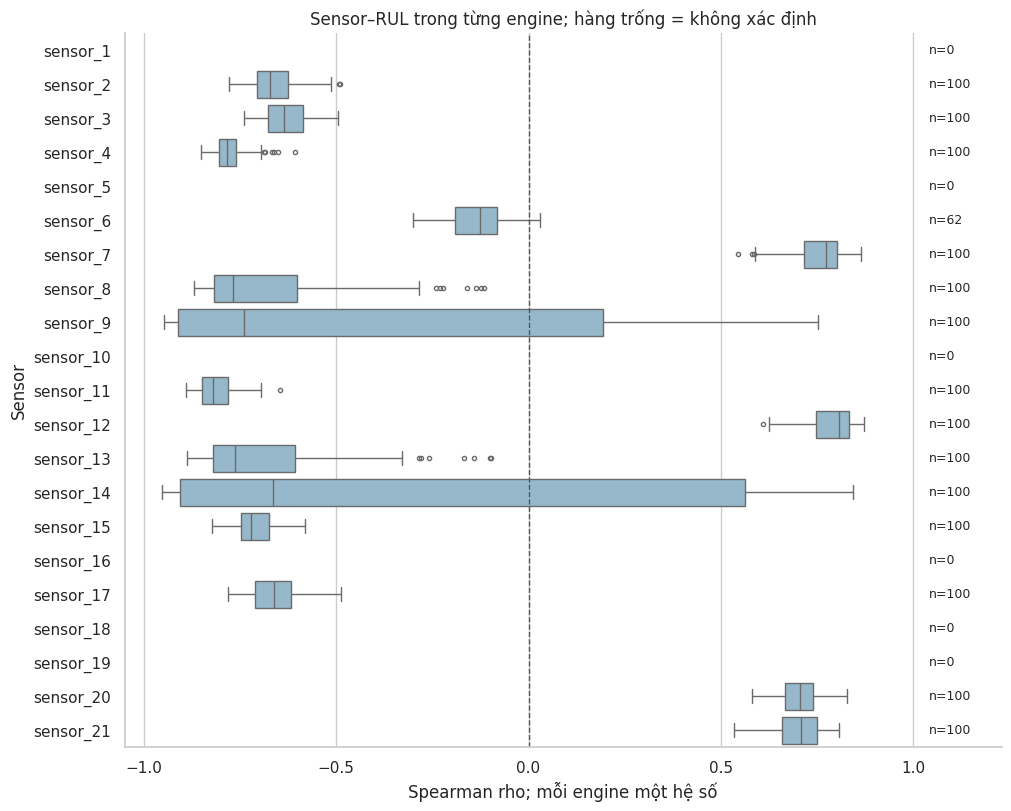

In [15]:
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
valid_correlations = correlations[correlations.defined]
sns.boxplot(valid_correlations, x="rho", y="sensor", order=list(SENSORS),
            color="#8dbbd3", ax=ax, fliersize=3)
ax.axvline(0, color="#555555", linewidth=1, linestyle="--")
for position, sensor in enumerate(SENSORS):
    count = int(correlation_summary.loc[sensor, "defined_engines"])
    ax.text(1.04, position, f"n={count}", va="center", fontsize=9)
ax.set(xlim=(-1.05, 1.23), xticks=[-1, -0.5, 0, 0.5, 1],
       xlabel="Spearman rho; mỗi engine một hệ số", ylabel="Sensor",
       title="Sensor–RUL trong từng engine; hàng trống = không xác định")
show_figure(fig, "sensor_rul_by_engine.png")

**Nhận xét.** Ba sensor có liên hệ mạnh và ổn định nhất với RUL là `sensor_11` (median rho −0,819,
Q25–Q75 từ −0,848 đến −0,780), `sensor_12` (0,808) và `sensor_4` (−0,784). Hộp của chúng hẹp,
tức là động cơ nào cũng cho kết quả tương tự. `sensor_9` và `sensor_14` thì ngược lại: median lần lượt
−0,739 và −0,663 nhưng Q75 lại dương (0,193 và 0,563), nghĩa là chiều liên hệ đổi dấu giữa các động cơ,
khớp với điều đã thấy ở mục 4. `sensor_6` chỉ có hệ số ở 62 động cơ và median gần 0 (−0,126).

## 6. Lưu thông tin tái lập

Ghi lại hash của file input, phiên bản thư viện và danh sách bảng/hình đã xuất vào `outputs/eda/run_info.json`.

In [16]:
run_info = {
    "input": "data/raw/train_FD001.txt",
    "input_sha256": hashlib.sha256(RAW_PATH.read_bytes()).hexdigest(),
    "python": platform.python_version(),
    "versions": {name: version(name) for name in
                 ("cmapss-rul", "pandas", "numpy", "scipy", "matplotlib", "seaborn", "ipykernel")},
    "sample_std_ddof": 1,
    "quantile_interpolation": "linear",
    "histogram_bins": 20,
    "test_data_used": False,
    "observations": len(train),
    "engines": len(lifetimes),
    "example_engine_ids": example_ids,
    "constant_measurements": constant_measurements,
    "tables": sorted(path.name for path in TABLES.glob("*.csv")),
    "figures": sorted(path.name for path in FIGURES.glob("*.png")),
}
(OUTPUT / "run_info.json").write_text(json.dumps(run_info, ensure_ascii=False, indent=2) + "\n",
                                      encoding="utf-8")
print(len(run_info["tables"]), "bảng CSV,", len(run_info["figures"]), "hình PNG")

12 bảng CSV, 11 hình PNG


## Tóm tắt

Tập train FD001 sạch: không thiếu dữ liệu, không trùng khóa. Tuổi thọ động cơ từ 128 đến 362 cycle,
lệch phải. Có 7 cột không đổi có thể bỏ qua khi làm mô hình, và `sensor_6` gần như không mang thông tin.
Nhóm sensor 11, 12, 4 (cùng các sensor tương quan mạnh với chúng) thay đổi đều đặn theo RUL ở mọi động cơ;
`sensor_9` và `sensor_14` có hành vi khác nhau giữa các động cơ.

Các nhận xét trên dựa vào toàn bộ tập train nên chỉ là giả thuyết để kiểm tra tiếp. Notebook 02 kiểm định
chênh lệch đầu/cuối đời của từng sensor; việc chọn sensor cho mô hình phải làm lại bên trong từng fold
khi huấn luyện để tránh rò rỉ dữ liệu.